In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import cartopy.crs as ccrs
import matplotlib.path as mpath
import cartopy.feature as cfeature
from matplotlib import gridspec
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter
from scipy import signal
import scipy
from scipy.stats import t
from scipy.stats import f
import os
from pyproj import CRS
import geopy.distance
# Imports and settings
import os, glob, warnings
import sys
import warnings
from warnings import filterwarnings
filterwarnings("ignore",category=DeprecationWarning)
filterwarnings("ignore", category=FutureWarning)
filterwarnings("ignore", category=UserWarning)
filterwarnings("ignore", category=RuntimeWarning)

#ls = xr.open_dataset('../data/lsm.nc').landseamask<=95

In [4]:
lsm_mask = '/lustre/orion/cli138/proj-shared/z7a/Storms_data/Storms_precipitation_notebooks/era5_land_sea_mask.nc'
lsm_mask = xr.open_dataset(lsm_mask)['lsm']
lsm_mask = lsm_mask.assign_coords(longitude=(((lsm_mask.longitude + 180) % 360) - 180)).sortby('longitude')
lsm_mask

<xarray.DataArray 'lsm' (valid_time: 1, latitude: 721, longitude: 1440)> Size: 4MB
[1038240 values with dtype=float32]
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 8B 2000-01-01
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
    expver      <U4 16B ...
  * longitude   (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Attributes: (12/32)
    GRIB_paramId:                             172
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               (0 - 1)
    long_name:                                Land-sea mask
    units:                                    (0 - 1)
    standard_name:                            land_binary_mask
    GRIB_surface:                             0.0

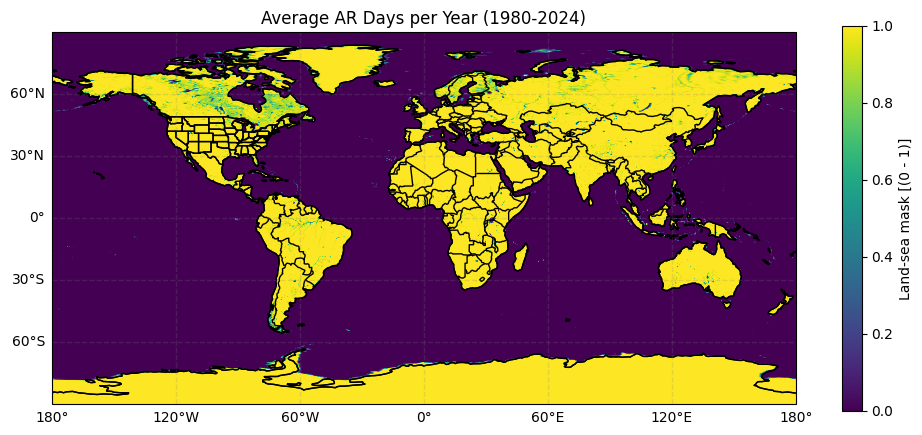

In [5]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
fig = plt.figure(figsize=(12, 5))
# assign axis and projection
ax = plt.axes(projection=ccrs.PlateCarree())
# add coastlines
ax.coastlines()
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)

# ax.set_extent([-180, 0, 10, 90], crs=ccrs.PlateCarree())

gl=ax.gridlines(draw_labels=True, linewidth=1, color='gray', alpha=0.2, linestyle='--') 
gl.top_labels = False
gl.right_labels = False

ax.coastlines(color='black')
# ax.set_title("Hurricanes Original")
# ax.gridlines()
# plot as above
lsm_mask.plot(ax=ax, cmap='viridis',transform=ccrs.PlateCarree())
plt.title('Average AR Days per Year (1980-2024)')
plt.show()

In [11]:
import h5py

file_path = "/lustre/orion/proj-shared/cli138/z7a/Storms_data/Storms_precipitation_notebooks/Percentile_ARs_detection/cache/preprocessed/era5_preprocessed_198105.h5"

with h5py.File(file_path, "r") as f:
    # List all top-level keys/groups
    print("Keys:")
    for key in f.keys():
        print(key)

    # Example: inspect one dataset
    # Replace 'your_dataset_name' with actual key
    data = f['BT_ds'][:]
    print(data.shape)

Keys:
BT_ds
IWV
ivt
ivt_grad
latitude
longitude
mslp
temp_500mb
time
vorticity
vorticity_grad
wind_speed
windhshear
(124, 721, 1440)


In [3]:
import h5py

file_path = "/lustre/orion/proj-shared/cli138/z7a/Storms_data/Storms_precipitation_notebooks/Percentile_ARs_detection/cache/preprocessed_v3/era5_preprocessed_198110.h5"

with h5py.File(file_path, "r") as f:
    # List all top-level keys/groups
    print("Keys:")
    for key in f.keys():
        print(key)

    # Example: inspect one dataset
    # Replace 'your_dataset_name' with actual key
    data = f['BT_ds'][:]
    print(data.shape)

Keys:
BT_ds
IWV
ivt
ivt_grad
latitude
longitude
mslp
temp_500mb
time
vorticity
vorticity_grad
wind_speed
windhshear
(124, 721, 1440)


In [ ]:
ETCs2 = '/lustre/orion/proj-shared/cli138/z7a/Storms_data/Storms_precipitation_notebooks/WNet_parallel_global_code/inference_runs/ema_checkpoint_epoch_54_primary_2006_2024/era5dara_200601_AR_detection.nc'
ETCs2 = xr.open_dataset(ETCs2)['AR_detection']
# ETCs = ETCs.assign_coords(longitude=(((lsm_mask.longitude + 180) % 360) - 180)).sortby('longitude')
ETCs2

In [3]:
ETCs = '/lustre/orion/proj-shared/cli138/z7a/Storms_data/Storms_precipitation_notebooks/WNet_parallel_global_code/inference_runs/ema_checkpoint_epoch_54_primary_2006_2024/era5dara_200601_AR_detection.nc'
ETCs = xr.open_dataset(ETCs)['AR_detection']
# ETCs = ETCs.assign_coords(longitude=(((lsm_mask.longitude + 180) % 360) - 180)).sortby('longitude')
ETCs

<xarray.DataArray 'AR_detection' (time: 124, latitude: 721, longitude: 1440)> Size: 515MB
[128741760 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 992B 2006-01-01 ... 2006-01-31T18:00:00
  * latitude   (latitude) float32 3kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
Attributes:
    long_name:    Atmospheric River Detection Probability
    units:        probability
    valid_range:  [0. 1.]
    description:  Post-processed atmospheric river detection probability from...

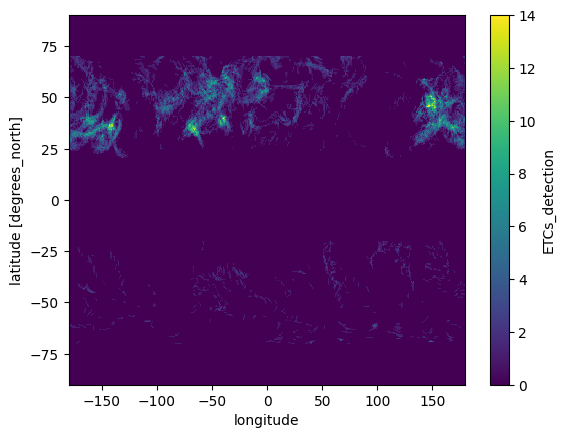

In [15]:
ETCs.sel(time='1980-01').sum('time').plot()

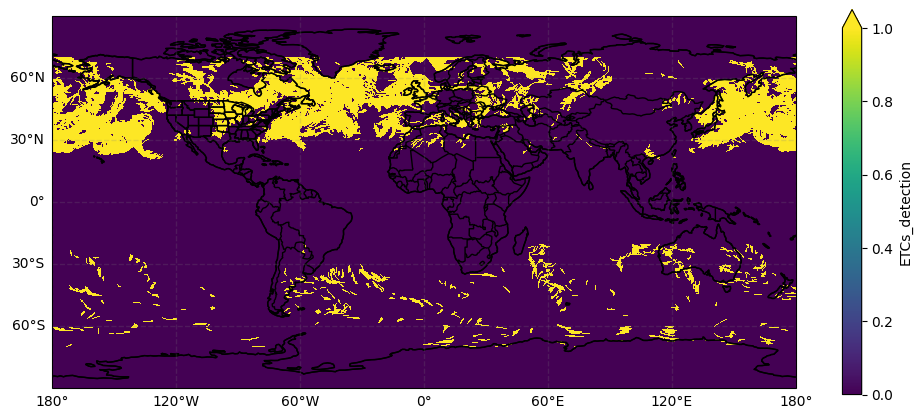

In [19]:

import cartopy.crs as ccrs
import cartopy.feature as cfeature
fig = plt.figure(figsize=(12, 5))
# assign axis and projection
ax = plt.axes(projection=ccrs.PlateCarree())
# add coastlines
ax.coastlines()
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)

# ax.set_extent([-180, 0, 10, 90], crs=ccrs.PlateCarree())

gl=ax.gridlines(draw_labels=True, linewidth=1, color='gray', alpha=0.2, linestyle='--') 
gl.top_labels = False
gl.right_labels = False

ax.coastlines(color='black')
# ax.set_title("Hurricanes Original")
# ax.gridlines()
# plot as above
ETCs.sel(time='1980-01').sum('time').plot(ax=ax, vmin=0, vmax=1, cmap='viridis',transform=ccrs.PlateCarree())
# plt.title('Average AR Days per Year (1980-2024)')
plt.show()